# Phân cụm dựa trên mật độ (DBSCAN) & Phân cụm phân cấp (Hierarchical)

Khi dữ liệu có hình thù kỳ lạ (cong, uốn lượn, lồng vào nhau) hoặc chứa nhiều điểm nhiễu (outliers), K-Means sẽ thất bại. Lúc này, ta cần dùng thuật toán **DBSCAN**.

**1. Khái niệm cốt lõi của DBSCAN:**
DBSCAN không cần biết trước số lượng cụm $K$. Nó gom cụm dựa trên hai tham số:
*   **Epsilon ($\epsilon$):** Bán kính vùng lân cận xung quanh một điểm.
*   **MinPts (min_samples):** Số lượng điểm tối thiểu phải có trong vùng bán kính $\epsilon$ để tạo thành một khu vực đông đúc (Dense region).

**2. Phân loại điểm dữ liệu:**
Dựa vào $\epsilon$ và MinPts, mỗi điểm dữ liệu sẽ rơi vào 1 trong 3 trạng thái:
*   **Core Point (Điểm lõi):** Có ít nhất `MinPts` điểm láng giềng trong bán kính $\epsilon$ (bao gồm cả chính nó). Điểm lõi đóng vai trò "hạt giống" mở rộng cụm.
*   **Border Point (Điểm biên):** Không đủ `MinPts` láng giềng, nhưng lại nằm trong bán kính $\epsilon$ của một điểm lõi.
*   **Noise / Outlier (Điểm nhiễu):** Không phải lõi, cũng không nằm gần lõi. DBSCAN sẽ trực tiếp gán nhãn `-1` cho các điểm này và loại bỏ chúng khỏi mọi cụm.

**3. Phân cụm phân cấp (Hierarchical Clustering):**
Ngoài DBSCAN, Agglomerative Clustering (từ dưới lên) cũng là một lựa chọn phổ biến. Ban đầu, mỗi điểm là 1 cụm riêng. Ở mỗi bước, 2 cụm gần nhau nhất (đo bằng linkage criteria như Single, Complete, Ward) sẽ được gộp lại cho đến khi tạo thành một cái cây duy nhất (Dendrogram). Cắt ngang Dendrogram ở một độ cao nhất định sẽ cho ra các cụm rời rạc.

In [1]:
import numpy as np
from utils.distances import euclidean_distance_matrix

class DBSCANScratch:
    """Thuật toán phân cụm dựa trên mật độ DBSCAN."""
    def __init__(self, eps=0.3, min_samples=5):
        self.eps = eps
        self.min_samples = min_samples
        self.labels = None

    def fit(self, X: np.ndarray):
        X = np.asarray(X)
        n_samples = X.shape[0]
        
        # Khởi tạo nhãn: -2 (chưa thăm), -1 (nhiễu/noise), >=0 (ID của cụm)
        self.labels = np.full(n_samples, -2) 
        cluster_id = 0
        
        # Tính sẵn ma trận khoảng cách để tối ưu tốc độ duyệt
        dist_matrix = euclidean_distance_matrix(X, X)
        
        for i in range(n_samples):
            if self.labels[i] != -2:
                continue # Bỏ qua điểm đã thăm
                
            # Tìm láng giềng trong bán kính epsilon
            neighbors = np.where(dist_matrix[i] <= self.eps)[0]
            
            if len(neighbors) < self.min_samples:
                # Không đủ đông -> Tạm thời đánh dấu là nhiễu
                self.labels[i] = -1 
            else:
                # Đủ điều kiện làm Core Point -> Mở rộng cụm
                self._expand_cluster(i, neighbors, cluster_id, dist_matrix)
                cluster_id += 1
                
        return self

    def _expand_cluster(self, point_idx, neighbors, cluster_id, dist_matrix):
        # Gán nhãn cho Core Point ban đầu
        self.labels[point_idx] = cluster_id
        
        # Dùng List để linh hoạt thêm các điểm láng giềng mới phát hiện vào cuối hàng đợi
        queue = list(neighbors)
        
        while queue:
            curr_point = queue.pop(0)
            
            if self.labels[curr_point] == -1:
                # Điểm từng bị coi là nhiễu nay được "cứu" bởi Core Point -> Trở thành Border Point
                self.labels[curr_point] = cluster_id
                
            elif self.labels[curr_point] == -2:
                # Điểm chưa thăm -> Gán vào cụm hiện tại
                self.labels[curr_point] = cluster_id
                
                # Kiểm tra xem điểm láng giềng này có phải là Core Point không?
                curr_neighbors = np.where(dist_matrix[curr_point] <= self.eps)[0]
                if len(curr_neighbors) >= self.min_samples:
                    # Nếu có, tiếp tục lan truyền (thêm láng giềng của nó vào hàng đợi)
                    queue.extend(curr_neighbors)
                    
    def fit_predict(self, X: np.ndarray):
        self.fit(X)
        return self.labels

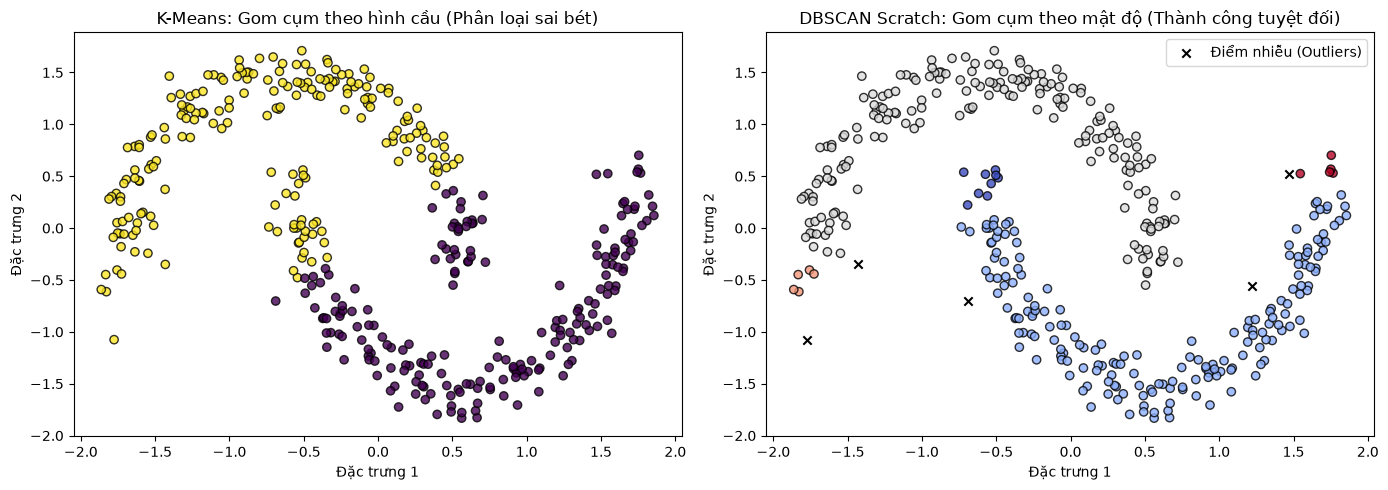

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.datasets import make_moons
from utils.preprocessing import StandardScaler

# 1. Sinh dữ liệu hình bán nguyệt lồng vào nhau (K-Means sẽ hoàn toàn thất bại ở đây)
X, _ = make_moons(n_samples=400, noise=0.08, random_state=42)

# Chuẩn hóa dữ liệu để khoảng cách epsilon có ý nghĩa
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Chạy DBSCAN (Scratch)
t0 = time.time()
# Thiết lập bán kính 0.2 và tối thiểu 5 điểm
model_dbscan = DBSCANScratch(eps=0.2, min_samples=5)
labels_dbscan = model_dbscan.fit_predict(X_scaled)
t_dbscan = (time.time() - t0) * 1000

# 3. Chạy K-Means (Sklearn) để đối chiếu
t0 = time.time()
model_kmeans = KMeans(n_clusters=2, random_state=42, n_init="auto").fit(X_scaled)
labels_kmeans = model_kmeans.labels_
t_kmeans = (time.time() - t0) * 1000

# 4. Trực quan hóa so sánh
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Đồ thị 1: Sự thất bại của K-Means
ax1.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels_kmeans, cmap='viridis', edgecolors='k', alpha=0.8)
ax1.set_title("K-Means: Gom cụm theo hình cầu (Phân loại sai bét)")
ax1.set_xlabel("Đặc trưng 1")
ax1.set_ylabel("Đặc trưng 2")

# Đồ thị 2: Sự chiến thắng của DBSCAN
# Lọc riêng các điểm nhiễu (nhãn -1) để vẽ màu đen
noise_mask = (labels_dbscan == -1)
core_mask = ~noise_mask

ax2.scatter(X_scaled[core_mask, 0], X_scaled[core_mask, 1], c=labels_dbscan[core_mask], cmap='coolwarm', edgecolors='k', alpha=0.8)
ax2.scatter(X_scaled[noise_mask, 0], X_scaled[noise_mask, 1], color='black', marker='x', label="Điểm nhiễu (Outliers)")

ax2.set_title("DBSCAN Scratch: Gom cụm theo mật độ (Thành công tuyệt đối)")
ax2.set_xlabel("Đặc trưng 1")
ax2.set_ylabel("Đặc trưng 2")
ax2.legend()

plt.tight_layout()
plt.show()